In [1]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score
)

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

wine = pd.read_csv(url, sep=";")
wine = wine.dropna()

print("Kích thước dữ liệu:", wine.shape)
display(wine.head())
print("Các cột dữ liệu:", wine.columns.tolist())

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Kích thước dữ liệu: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Các cột dữ liệu: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008


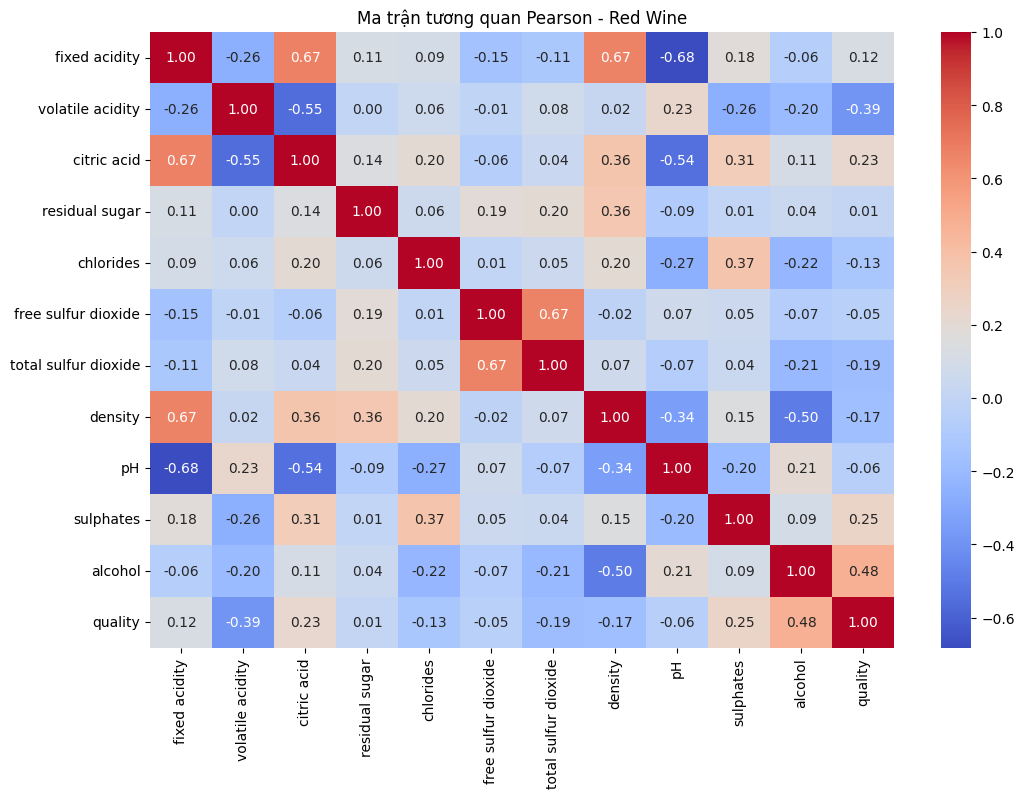

Các cột bị loại bỏ: []
Kích thước dữ liệu sau xử lý: (1599, 12)


In [2]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

corr = wine.corr(method="pearson")

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan Pearson - Red Wine")
plt.show()

columns_to_drop = set()

for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) > 0.9:
            col = corr.columns[i]
            if col != "quality":
                columns_to_drop.add(col)

wine = wine.drop(columns=list(columns_to_drop))

print("Các cột bị loại bỏ:", list(columns_to_drop))
print("Kích thước dữ liệu sau xử lý:", wine.shape)

In [3]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

features = wine.drop(columns=["quality"])
labels = wine["quality"]

print("Features:")
display(features.head())

print("Labels:")
display(labels.head())

print("Kích thước Features:", features.shape)
print("Kích thước Labels:", labels.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Features:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


Labels:


,quality
0,5
1,5
2,5
3,6
4,5


Kích thước Features: (1599, 11)
Kích thước Labels: (1599,)


In [4]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

features_encoded = pd.get_dummies(features)

print("Dữ liệu sau khi chuyển đổi:")
display(features_encoded.head())

print("Kích thước dữ liệu:", features_encoded.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Dữ liệu sau khi chuyển đổi:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


Kích thước dữ liệu: (1599, 11)


In [5]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

X_train, X_test, y_train, y_test = train_test_split(
    features_encoded,
    labels,
    test_size=0.3,
    random_state=42
)

print("Số dòng huấn luyện:", len(X_train))
print("Số dòng kiểm thử:", len(X_test))
print("Tỷ lệ huấn luyện:", len(X_train) / len(wine))
print("Tỷ lệ kiểm thử:", len(X_test) / len(wine))

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Số dòng huấn luyện: 1119
Số dòng kiểm thử: 480
Tỷ lệ huấn luyện: 0.699812382739212
Tỷ lệ kiểm thử: 0.300187617260788


Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn ID3:
[[  0   0   1   0   0   0]
 [  0   2   5   9   1   0]
 [  2  15 130  43   5   0]
 [  0   6  43 125  25   1]
 [  0   0   3  27  28   3]
 [  0   0   2   0   2   2]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.09      0.12      0.10        17
           5       0.71      0.67      0.69       195
           6       0.61      0.62      0.62       200
           7       0.46      0.46      0.46        61
           8       0.33      0.33      0.33         6

    accuracy                           0.60       480
   macro avg       0.37      0.37      0.37       480
weighted avg       0.61      0.60      0.60       480

Accuracy: 0.5979166666666667
Precision: 0.6079146241830066
Recall: 0.5979166666666667


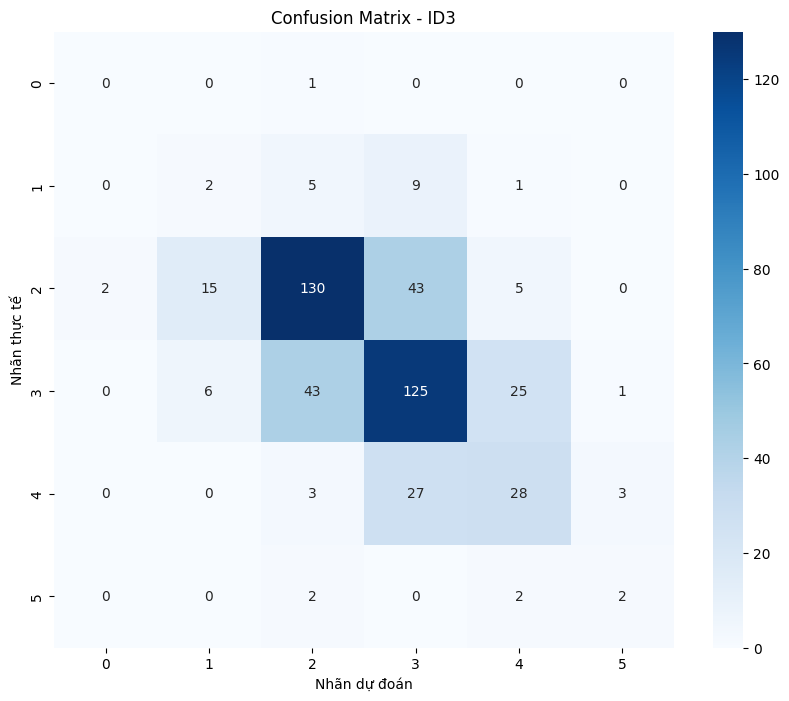

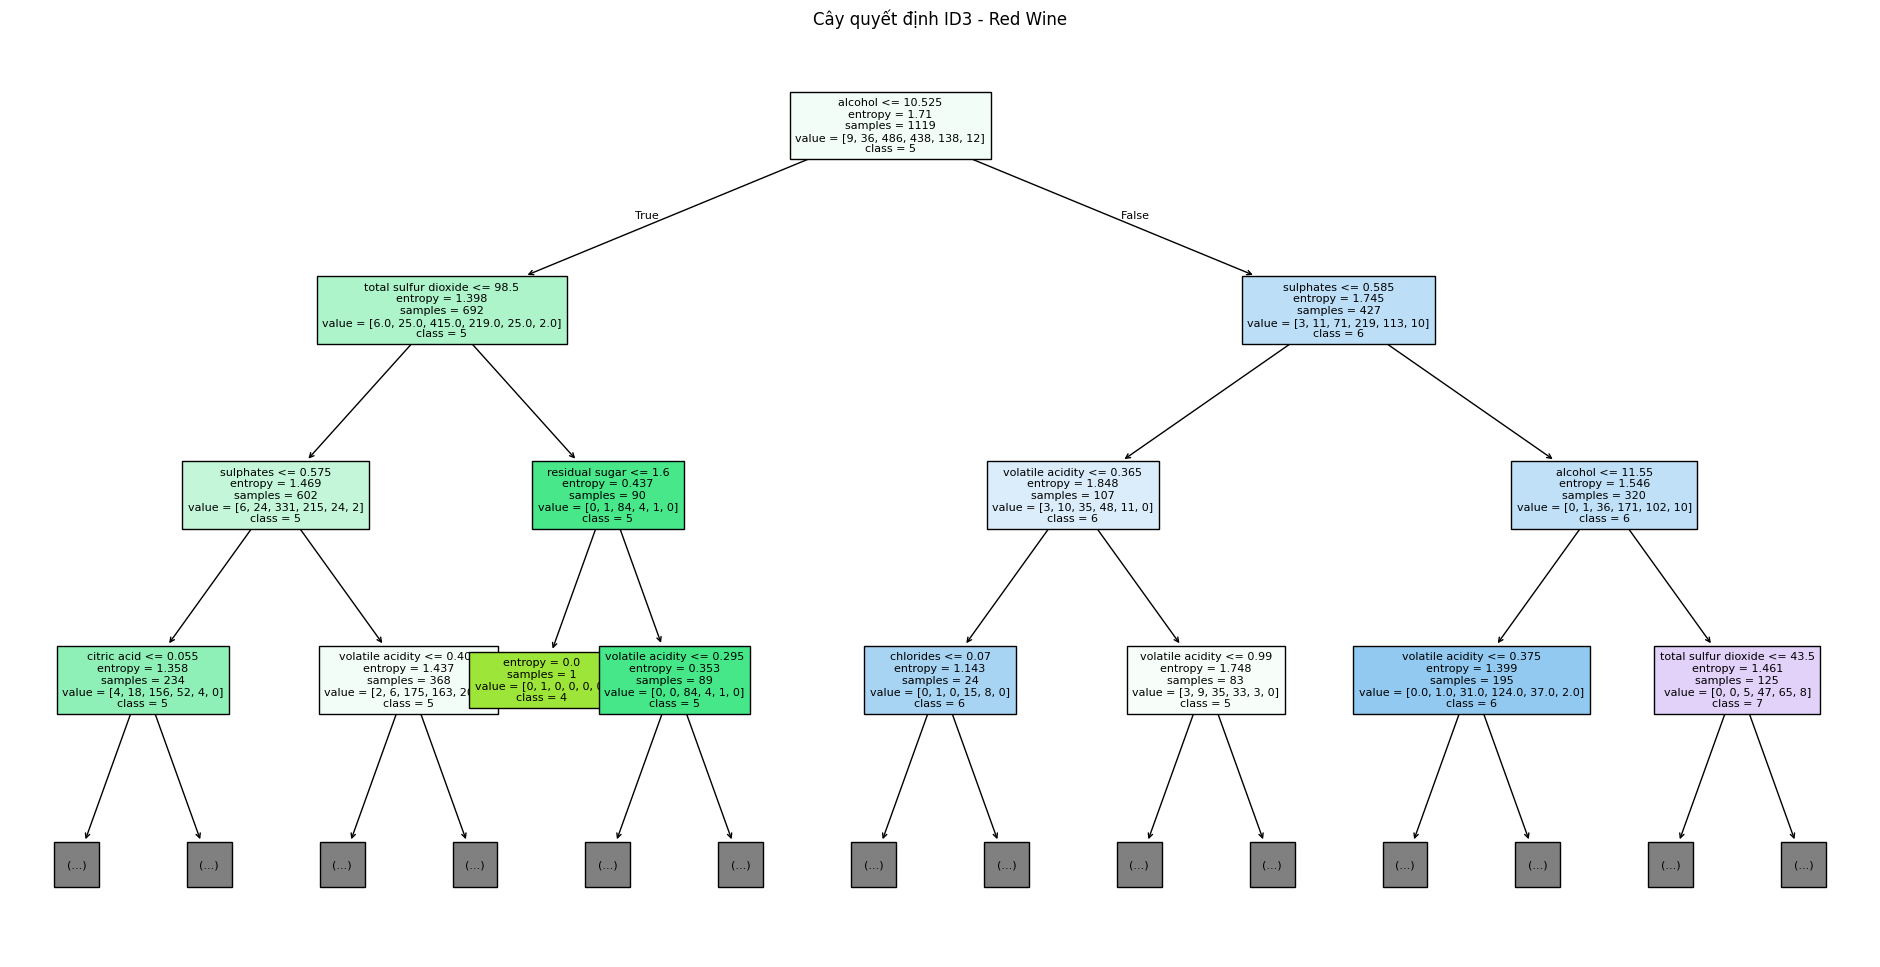

In [6]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

id3_model.fit(X_train, y_train)
y_pred_id3 = id3_model.predict(X_test)

cm_id3 = confusion_matrix(y_test, y_pred_id3)

print("Ma trận nhầm lẫn ID3:")
print(cm_id3)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_id3, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_id3))
print("Precision:", precision_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))

plt.figure(figsize=(10, 8))
sns.heatmap(cm_id3, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - ID3")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    id3_model,
    feature_names=X_train.columns,
    class_names=[str(x) for x in id3_model.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định ID3 - Red Wine")
plt.savefig("wine_ID3.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn CART:
[[  0   0   1   0   0   0]
 [  0   1  10   5   1   0]
 [  1   8 126  58   2   0]
 [  0   5  48 121  26   0]
 [  0   1   6  26  26   2]
 [  0   0   0   3   2   1]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.60      0.59       200
           7       0.46      0.43      0.44        61
           8       0.33      0.17      0.22         6

    accuracy                           0.57       480
   macro avg       0.35      0.32      0.33       480
weighted avg       0.57      0.57      0.57       480

Accuracy: 0.5729166666666666
Precision: 0.5691909618052456
Recall: 0.5729166666666666


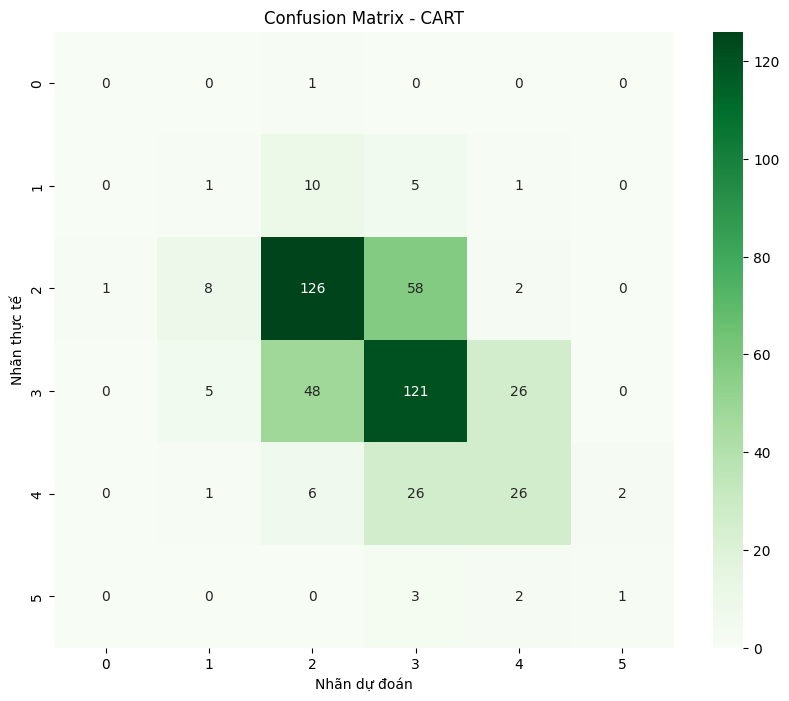

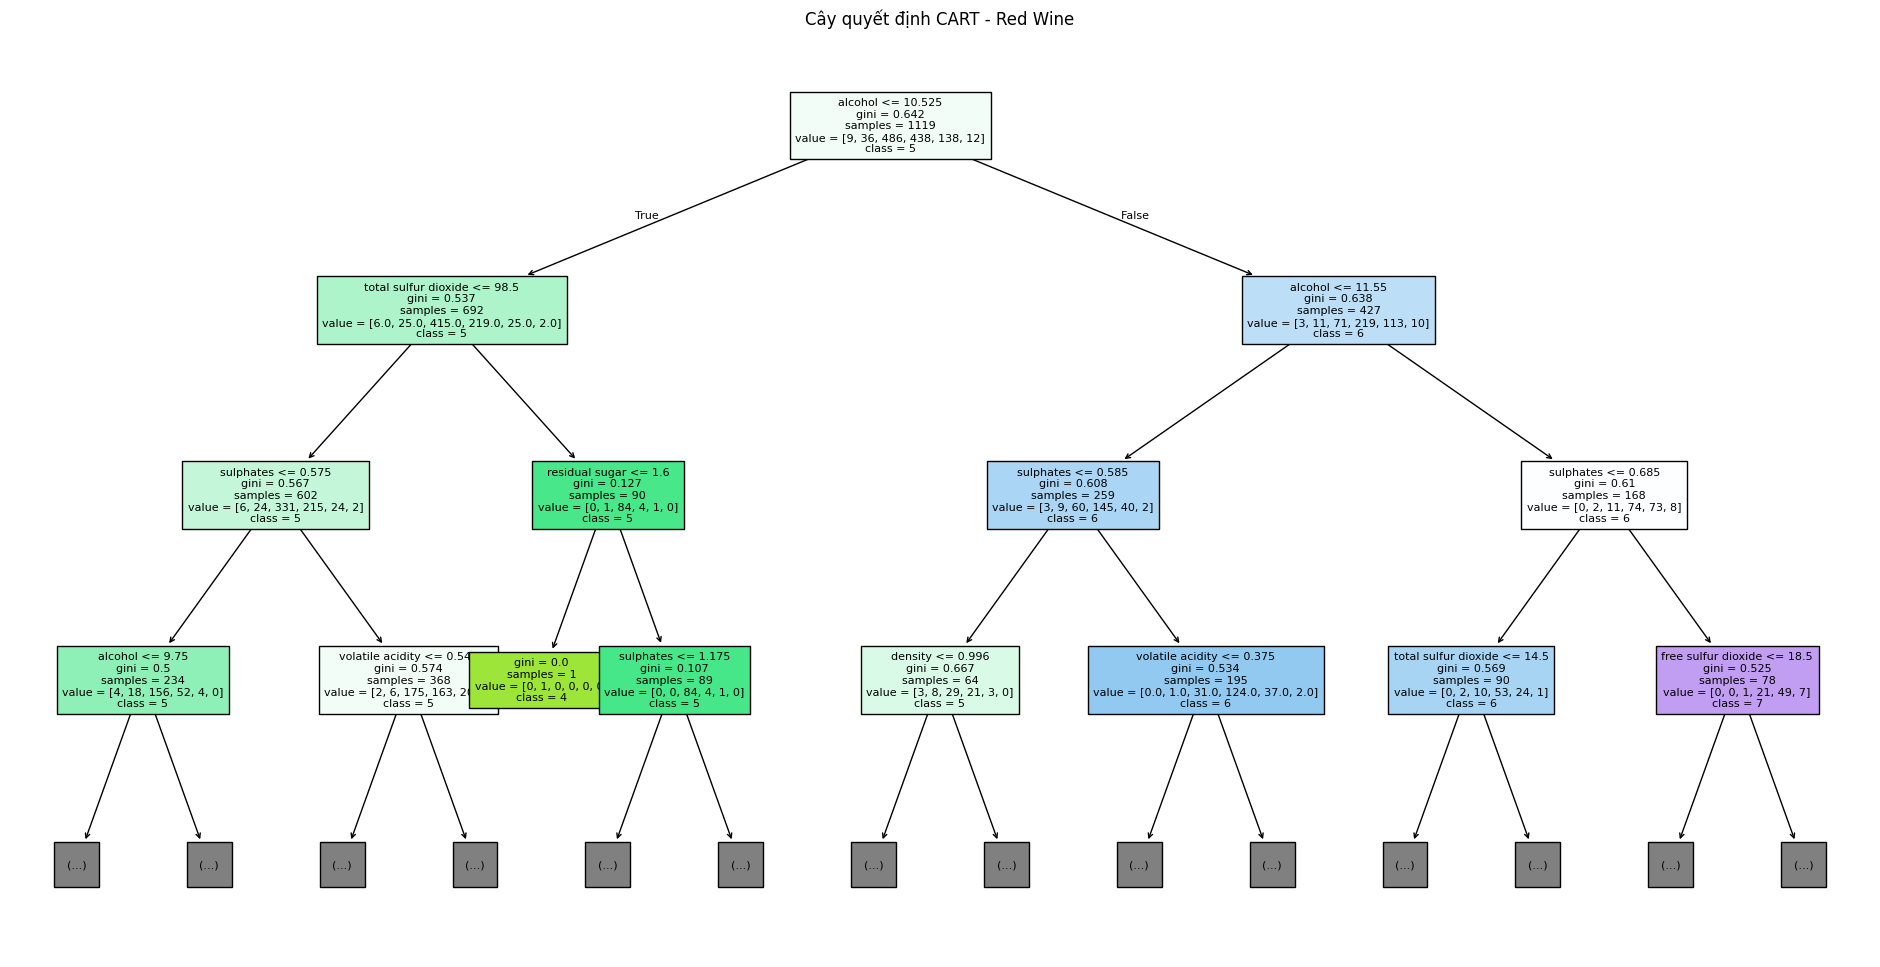

In [7]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_model.fit(X_train, y_train)
y_pred_cart = cart_model.predict(X_test)

cm_cart = confusion_matrix(y_test, y_pred_cart)

print("Ma trận nhầm lẫn CART:")
print(cm_cart)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_cart, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_cart))
print("Precision:", precision_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))

plt.figure(figsize=(10, 8))
sns.heatmap(cm_cart, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix - CART")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    cart_model,
    feature_names=X_train.columns,
    class_names=[str(x) for x in cart_model.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định CART - Red Wine")
plt.savefig("wine_CART.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn Naïve Bayes:
[[  0   0   1   0   0   0]
 [  1   2   8   6   0   0]
 [  0   6 121  63   5   0]
 [  0   9  46 107  35   3]
 [  0   0   3  28  30   0]
 [  0   0   0   1   5   0]]

Báo cáo phân loại:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480

Accuracy: 0.5416666666666666
Precision: 0.5470955965844574
Recall: 0.5416666666666666


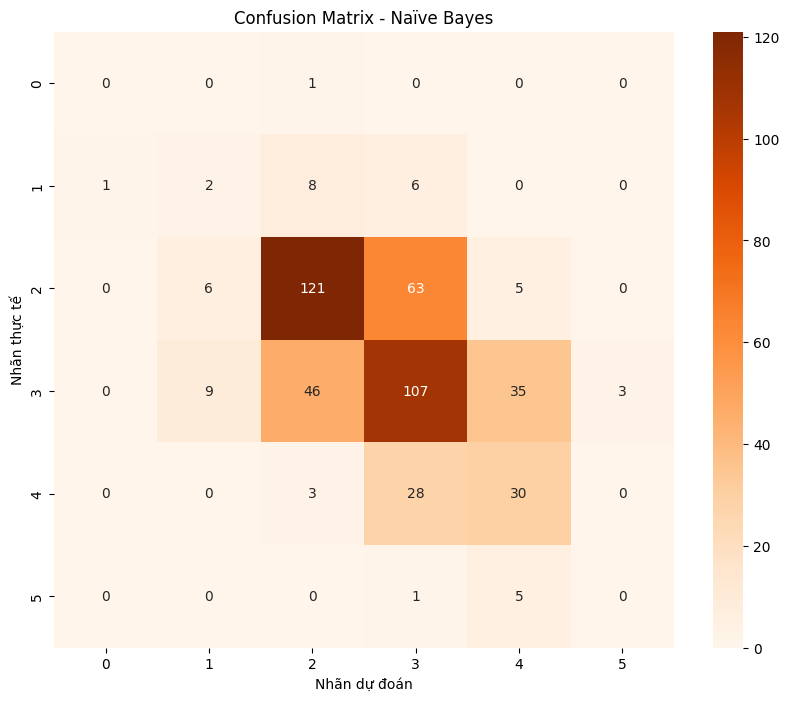

In [8]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

cm_nb = confusion_matrix(y_test, y_pred_nb)

print("Ma trận nhầm lẫn Naïve Bayes:")
print(cm_nb)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))

plt.figure(figsize=(10, 8))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Oranges")
plt.title("Confusion Matrix - Naïve Bayes")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008


,Mô hình,Accuracy,Precision,Recall,F1-score
0,ID3,0.597917,0.607915,0.597917,0.602574
1,CART,0.572917,0.569191,0.572917,0.570363
2,Naïve Bayes,0.541667,0.547096,0.541667,0.543265


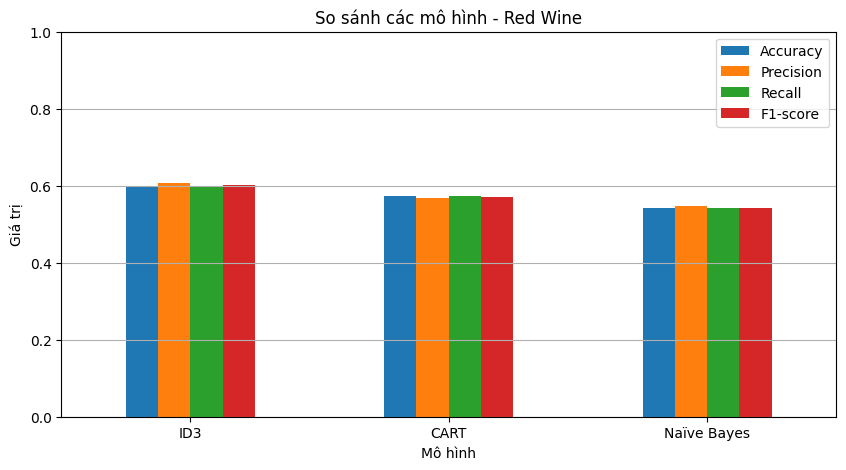

Mô hình có Accuracy cao nhất: ID3


In [9]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

results_wine = pd.DataFrame({
    "Mô hình": ["ID3", "CART", "Naïve Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_id3),
        accuracy_score(y_test, y_pred_cart),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ]
})

display(results_wine)

results_wine.set_index("Mô hình")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("So sánh các mô hình - Red Wine")
plt.ylabel("Giá trị")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

print(
    "Mô hình có Accuracy cao nhất:",
    results_wine.loc[results_wine["Accuracy"].idxmax(), "Mô hình"]
)